# Step 13 — Channel Flow (Poiseuille) and Taylor–Green Vortices

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step13_channel_flow.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

The last step checks the incompressible Navier–Stokes solver of step 12 against two exact solutions. Each one only holds with the right boundaries, so each gets its own configuration of the same model:

- **Part A, Poiseuille flow:** a re-entrant channel, periodic in $x$ with no-slip walls in $y$, driven by a uniform pressure gradient. We spin it up from rest and follow both the start-up and the steady parabolic profile.
- **Part B, Taylor–Green vortices:** a doubly periodic box, where a lattice of vortices decays at exactly the viscous rate.

**What you'll learn:**

1. How the problem modes of `IncompressibleNS2D` set the boundary conditions
2. How to validate a solver against a transient and a steady exact solution, and how the error falls with the grid
3. How to differentiate the channel's flux with respect to viscosity and check it against the closed form

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The equations

As in step 12, the solver advances the vorticity and recovers the velocity from a streamfunction:

$$
\frac{\partial \omega}{\partial t} + u \frac{\partial \omega}{\partial x} + v \frac{\partial \omega}{\partial y} = \nu \nabla^2 \omega
$$

$$
\nabla^2 \psi = -\omega
$$

$$
u = \frac{\partial \psi}{\partial y}
$$

$$
v = -\frac{\partial \psi}{\partial x}
$$

### Symbols

Everything is nondimensional.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x$, $y$ | spatial coordinates | $\mathbb{R}$ |
| $t$ | time | $\mathbb{R}$ |
| $\mathbf{v} = (u, v)$ | velocity | $\mathbb{R}^2$ |
| $\omega$, $\psi$ | vorticity and streamfunction | $\mathbb{R}$ |
| $\nu$ | kinematic viscosity, the model's differentiable parameter | $\mathbb{R}_{>0}$ |
| $G$ | uniform pressure gradient driving the channel, $G = -\partial p / \partial x$ | $\mathbb{R}$ |
| $Q$ | flux through the channel, $Q = \psi(L_y) - \psi(0)$ | $\mathbb{R}$ |
| $\kappa$ | wavenumber of the Taylor–Green vortices | $\mathbb{R}_{>0}$ |
| $L_x$, $L_y$ | domain lengths | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x$, $\Delta y$ | grid spacings | $\mathbb{R}_{>0}$ |
| $\Delta t$ | time step | $\mathbb{R}_{>0}$ |

## Boundary conditions

The arrays carry a one-cell ghost ring. In an array with `N` rows, the streamfunction solve puts the walls on rows `0` and `N - 2`, and row `N - 1` is a ghost; columns work the same way. The `problem` argument picks the boundaries:

| `problem` | $x$ | $y$ | Streamfunction solve |
| --- | --- | --- | --- |
| `"cavity"` (step 12) | no-slip walls | no-slip walls, moving lid on top | $\psi = 0$ on every wall (DST) |
| `"channel"` (Part A) | periodic | stationary no-slip walls | periodic in $x$; $\psi = 0$ below and $\psi = Q$ above |
| `"periodic"` (Part B) | periodic | periodic | FFT on both axes |

On a stationary no-slip wall the vorticity comes from Thom's formula, which uses the wall's own streamfunction value $\psi_\text{wall}$ and the first interior node one spacing $\Delta y$ away:

$$
\omega_\text{wall} = \frac{2 (\psi_\text{wall} - \psi_\text{interior})}{\Delta y^2}
$$

The flux $Q$ is part of the channel's state. Averaging the $x$-momentum equation over $x$ and integrating across the channel leaves the pressure gradient and the wall stresses, since $\partial u / \partial y = -\omega$ and $u v = 0$ on the walls:

$$
\frac{\mathrm{d}Q}{\mathrm{d}t} = G L_y - \nu \left(\bar{\omega}(L_y) - \bar{\omega}(0)\right)
$$

where $\bar{\omega}$ is the wall vorticity averaged over $x$.

In [2]:
import diffrax as dfx
import einx
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## Part A: Poiseuille flow in a re-entrant channel

A uniform pressure gradient $G$ drives fluid along a channel between two walls at $y = 0$ and $y = L_y$. The steady state is the parabolic Poiseuille profile, which carries a flux $Q_\infty$:

$$
u(y) = \frac{G}{2 \nu} y (L_y - y)
$$

$$
Q_\infty = \frac{G L_y^3}{12 \nu}
$$

Starting from rest, each odd sine mode of that profile switches on with its own viscous time, and the flux follows the series

$$
Q(t) = Q_\infty \left(1 - \frac{96}{\pi^4} \sum_{n \text{ odd}} \frac{1}{n^4} \exp\left(-\frac{n^2 \pi^2 \nu t}{L_y^2}\right)\right)
$$

In [4]:
# Shapes: N_Ωx,x = N_Ωx,y = 32 interior cells;
# A = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

num_cells = 32
channel_length = 2.0
channel_width = 1.0
pressure_gradient = 1.0
channel_viscosity = 0.1

# today (sesmax_core)
channel_model = sxt.IncompressibleNS2D.create(
    nx=num_cells,
    ny=num_cells,
    Lx=channel_length,
    Ly=channel_width,
    nu=channel_viscosity,
    problem="channel",
    pressure_gradient=pressure_gradient,
)

# Q_∞ = G L_y³ / (12 ν)
steady_flux = pressure_gradient * channel_width**3 / (12.0 * channel_viscosity)

print(f"Grid: {channel_model.grid.Ny} x {channel_model.grid.Nx} (including ghosts)")
print(f"Steady flux Q_inf = {steady_flux:.5f}")
print(f"Steady peak velocity = {steady_flux * 1.5 / channel_width:.4f}")

Grid: 34 x 34 (including ghosts)
Steady flux Q_inf = 0.83333
Steady peak velocity = 1.2500


### Spin-up from rest

The state starts at rest with $\omega = 0$ and $Q = 0$. The slowest mode decays on the time scale $L_y^2 / (\pi^2 \nu) \approx 1$, so by $t = 10$ the channel is steady. The explicit step obeys the diffusive limit $\Delta t < \Delta y^2 / (4 \nu)$.

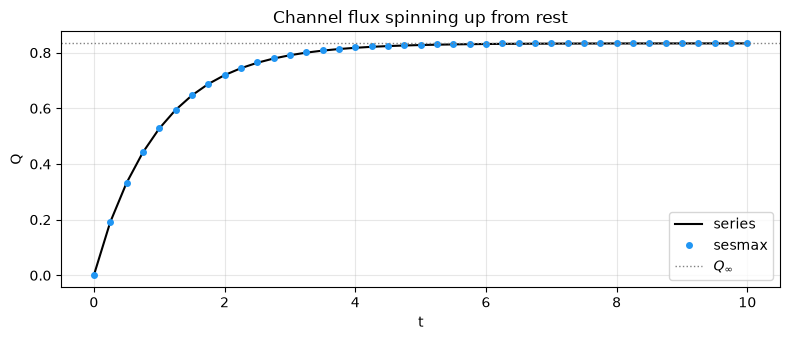

Final flux: 0.83492 (Q_inf = 0.83333)
Max flux error over the spin-up: 0.20% of Q_inf


In [5]:
# Shapes: N_T = 41 saved times; A = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

end_time = 10.0
time_step = 0.002

# tₖ = k t₁ / (N_T − 1)
save_times = jnp.linspace(0.0, end_time, 41)  # → (N_T,)
# ω = 0, Q = 0
rest_omega = jnp.zeros((channel_model.grid.Ny, channel_model.grid.Nx))  # → A
# today (sesmax_core)
rest_state = sxt.NSVorticityState(omega=rest_omega)

# today (sesmax_core, diffrax)
channel_solution = channel_model.integrate(  # ω → N_T × A, Q → (N_T,)
    rest_state,
    t0=0.0,
    t1=end_time,
    dt=time_step,
    saveat=dfx.SaveAt(ts=save_times),
    max_steps=10_000,
)


def startup_flux(viscosity, time):
    """Q(t) from rest, summed over the odd modes n < 400."""
    odd_modes = jnp.arange(1, 400, 2.0)
    # λₙ = n² π² ν / L_y²
    decay_rate = odd_modes**2 * jnp.pi**2 * viscosity / channel_width**2
    # Σ n⁻⁴ exp(−λₙ t)
    tail = jnp.sum(jnp.exp(-decay_rate * time) / odd_modes**4)
    # Q_∞ = G L_y³ / (12 ν)
    final_flux = pressure_gradient * channel_width**3 / (12.0 * viscosity)
    # Q(t) = Q_∞ (1 − (96 / π⁴) Σ n⁻⁴ exp(−λₙ t))
    return final_flux * (1.0 - 96.0 / jnp.pi**4 * tail)


# today (jax)
exact_flux = jax.vmap(startup_flux, in_axes=(None, 0))(channel_viscosity, save_times)
numerical_flux = channel_solution.ys.flux  # → (N_T,)
# max |Q(tₖ) − Qᵉˣᵃᶜᵗ(tₖ)| / Q_∞
flux_error = jnp.max(jnp.abs(numerical_flux - exact_flux)) / steady_flux  # → ()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(save_times, exact_flux, "k-", lw=1.5, label="series")
ax.plot(save_times, numerical_flux, "o", color="#2196F3", ms=4, label="sesmax")
ax.axhline(steady_flux, color="grey", ls=":", lw=1.0, label=r"$Q_\infty$")
ax.set_xlabel("t")
ax.set_ylabel("Q")
ax.set_title("Channel flux spinning up from rest")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Final flux: {float(numerical_flux[-1]):.5f} (Q_inf = {steady_flux:.5f})")
print(f"Max flux error over the spin-up: {float(flux_error):.2%} of Q_inf")

### The steady profile

At $t = 10$ the velocity follows from centred differences of the streamfunction across the rows, $u_j = (\psi_{j+1} - \psi_{j-1}) / (2 \Delta y)$, averaged along the channel. The flow does not vary in $x$, so the average only removes round-off.

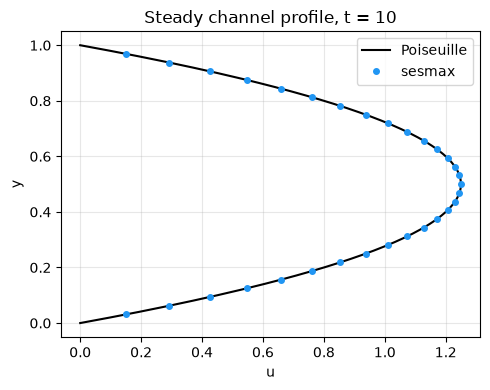

Velocity RMS error: 5.01e-05
Peak velocity:      1.250


In [6]:
# Shapes: N_Ωx,y − 1 interior rows; A = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
final_state = sxt.NSVorticityState(
    omega=channel_solution.ys.omega[-1],
    flux=channel_solution.ys.flux[-1],
)
# today (sesmax_core)
final_state = channel_model.apply_boundary_conditions(final_state)
# today (sesmax_core)
channel_diagnostics = channel_model.diagnose(final_state)
streamfunction = channel_diagnostics.psi  # → A

# ψ̄ⱼ = mean over the periodic columns
mean_psi = einx.mean("y [x] -> y", streamfunction[:, 1:-1])  # → (N_Ωx,y + 2,)
# uⱼ = (ψ̄ⱼ₊₁ − ψ̄ⱼ₋₁) / (2 Δy), rows 1 … N_Ωx,y − 1
psi_above = mean_psi[2 : num_cells + 1]  # → (N_Ωx,y − 1,)
psi_below = mean_psi[0 : num_cells - 1]  # → (N_Ωx,y − 1,)
numerical_u = (psi_above - psi_below) / (2.0 * channel_model.grid.dy)
# yⱼ = j Δy
row_position = jnp.arange(1, num_cells) * channel_model.grid.dy  # → (N_Ωx,y − 1,)
# u(y) = (G / 2ν) y (L_y − y)
poiseuille_scale = pressure_gradient / (2.0 * channel_viscosity)
poiseuille_u = poiseuille_scale * row_position * (channel_width - row_position)
# ‖u − uᵉˣᵃᶜᵗ‖_RMS
velocity_rms_error = jnp.sqrt(jnp.mean((numerical_u - poiseuille_u) ** 2))  # → ()
# yᶠⁱⁿᵉ on [0, L_y]
fine_position = jnp.linspace(0.0, channel_width, 200)  # → (200,)
fine_poiseuille = poiseuille_scale * fine_position * (channel_width - fine_position)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fine_poiseuille, fine_position, "k-", lw=1.5, label="Poiseuille")
ax.plot(numerical_u, row_position, "o", color="#2196F3", ms=4, label="sesmax")
ax.set_xlabel("u")
ax.set_ylabel("y")
ax.set_title(f"Steady channel profile, t = {end_time:.0f}")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

peak_velocity = jnp.max(poiseuille_u)  # → ()
print(f"Velocity RMS error: {float(velocity_rms_error):.2e}")
print(f"Peak velocity:      {float(peak_velocity):.3f}")

## Part B: Taylor–Green vortices on a periodic box

On a doubly periodic box of side $L$, the vortex lattice with wavenumber $\kappa = 2\pi / L$,

$$
\omega(x, y, t) = 2 \kappa \sin(\kappa x) \sin(\kappa y) \exp(-2 \nu \kappa^2 t)
$$

solves the full nonlinear equations: $\psi = \omega / (2\kappa^2)$ is proportional to $\omega$, so the advection term $u \frac{\partial \omega}{\partial x} + v \frac{\partial \omega}{\partial y}$ vanishes and each vortex simply decays at the viscous rate $2 \nu \kappa^2$. The velocity amplitude starts at one.

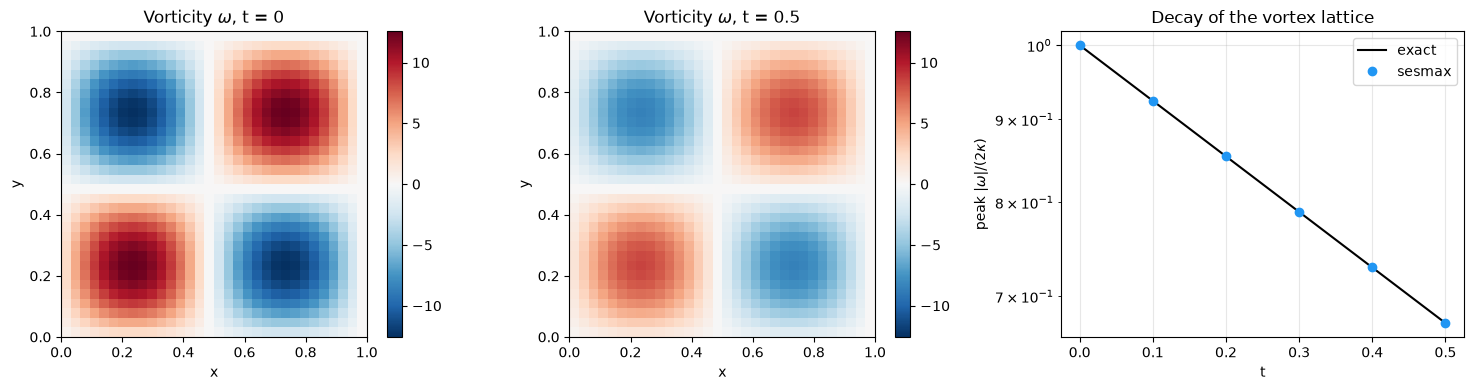

Peak ratio at t = 0.5: 0.67420
Exact decay factor:        0.67383
RMS vorticity error:       1.264e-02


In [7]:
# Shapes: N_Ωx,x = N_Ωx,y = 32 interior cells; N_T = 6 saved times;
# A = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

box_viscosity = 0.01
box_time = 0.5
# κ = 2π / L, L = 1
wavenumber = 2.0 * jnp.pi


def taylor_green(model, time):
    """Exact Taylor–Green vorticity on the model's nodes at time t."""
    # xᵢ = i Δx, yⱼ = j Δy
    node_x = jnp.arange(model.grid.Nx) * model.grid.dx
    node_y = jnp.arange(model.grid.Ny) * model.grid.dy
    grid_x, grid_y = jnp.meshgrid(node_x, node_y)  # → A each
    # e^(−2νκ²t)
    decay = jnp.exp(-2.0 * model.params.nu * wavenumber**2 * time)  # → ()
    # ω = 2κ sin(κx) sin(κy) e^(−2νκ²t)
    lattice = jnp.sin(wavenumber * grid_x) * jnp.sin(wavenumber * grid_y)
    return 2.0 * wavenumber * lattice * decay


# today (sesmax_core)
box_model = sxt.IncompressibleNS2D.create(
    nx=num_cells,
    ny=num_cells,
    nu=box_viscosity,
    problem="periodic",
    method="upwind3",
)
box_times = jnp.linspace(0.0, box_time, 6)  # → (N_T,)
# today (sesmax_core, diffrax)
box_solution = box_model.integrate(  # ω → N_T × A
    sxt.NSVorticityState(omega=taylor_green(box_model, 0.0)),
    t0=0.0,
    t1=box_time,
    dt=0.001,
    saveat=dfx.SaveAt(ts=box_times),
)

interior = (slice(1, -1), slice(1, -1))
# maxᵢⱼ |ωᵢⱼ(tₖ)| / (2κ)
interior_omega = box_solution.ys.omega[:, *interior]  # → N_T × N_Ωx,y × N_Ωx,x
numerical_peak = einx.max("t [y x] -> t", jnp.abs(interior_omega)) / (2.0 * wavenumber)
# e^(−2νκ²t)
exact_peak = jnp.exp(-2.0 * box_viscosity * wavenumber**2 * box_times)  # → (N_T,)
# ω(t₁) − ωᵉˣᵃᶜᵗ(t₁)
final_difference = box_solution.ys.omega[-1] - taylor_green(box_model, box_time)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fields = [
    (box_solution.ys.omega[0], "t = 0"),
    (box_solution.ys.omega[-1], f"t = {box_time}"),
]
for ax, (field, label) in zip(axes[:2], fields, strict=True):
    image = ax.imshow(
        field[interior],
        origin="lower",
        extent=(0.0, 1.0, 0.0, 1.0),
        cmap="RdBu_r",
        vmin=-2.0 * float(wavenumber),
        vmax=2.0 * float(wavenumber),
    )
    ax.set_title(rf"Vorticity $\omega$, {label}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(image, ax=ax)
axes[2].semilogy(box_times, exact_peak, "k-", lw=1.5, label="exact")
axes[2].semilogy(box_times, numerical_peak, "o", color="#2196F3", label="sesmax")
axes[2].set_xlabel("t")
axes[2].set_ylabel(r"peak $|\omega| / (2\kappa)$")
axes[2].set_title("Decay of the vortex lattice")
axes[2].legend()
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rms_difference = jnp.sqrt(jnp.mean(final_difference[interior] ** 2))
print(f"Peak ratio at t = {box_time}: {float(numerical_peak[-1]):.5f}")
print(f"Exact decay factor:        {float(exact_peak[-1]):.5f}")
print(f"RMS vorticity error:       {float(rms_difference):.3e}")

### Convergence with the grid

The advection scheme sets how fast the error falls. First-order upwinding adds numerical diffusion that damps the vortices faster than $\nu$ alone, and its error falls by less than half with each refinement. The third-order upwind reconstruction converges at close to third order on these grids.

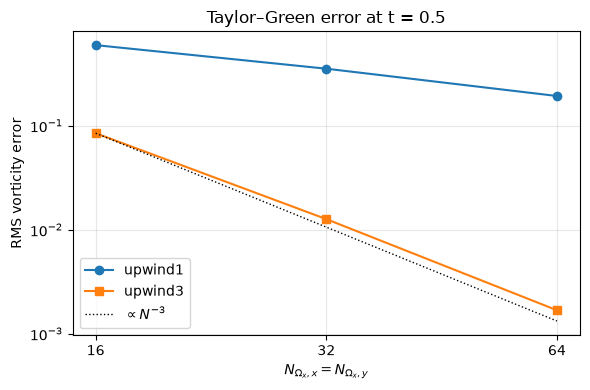

   n    upwind1    upwind3
  16  5.957e-01  8.473e-02
  32  3.535e-01  1.264e-02
  64  1.932e-01  1.682e-03


In [8]:
# Shapes: N_Ωx,x = N_Ωx,y = n interior cells for n in resolutions

resolutions = [16, 32, 64]
methods = ["upwind1", "upwind3"]
errors = {method: [] for method in methods}

for method in methods:
    for resolution in resolutions:
        # today (sesmax_core)
        model = sxt.IncompressibleNS2D.create(
            nx=resolution,
            ny=resolution,
            nu=box_viscosity,
            problem="periodic",
            method=method,
        )
        # today (sesmax_core, diffrax)
        solution = model.integrate(
            sxt.NSVorticityState(omega=taylor_green(model, 0.0)),
            t0=0.0,
            t1=box_time,
            dt=0.001,
            saveat=dfx.SaveAt(t1=True),
        )
        # ω(t₁) − ωᵉˣᵃᶜᵗ(t₁)
        difference = solution.ys.omega[0] - taylor_green(model, box_time)
        # ‖e‖_RMS over the interior
        error = jnp.sqrt(jnp.mean(difference[interior] ** 2))
        errors[method].append(float(error))

fig, ax = plt.subplots(figsize=(6, 4))
for method, marker in zip(methods, ["o", "s"], strict=True):
    ax.loglog(resolutions, errors[method], f"{marker}-", label=method)
reference = [errors["upwind3"][0] * (resolutions[0] / n) ** 3 for n in resolutions]
ax.loglog(resolutions, reference, "k:", lw=1.0, label=r"$\propto N^{-3}$")
ax.set_xticks(resolutions, labels=[str(n) for n in resolutions])
ax.minorticks_off()
ax.set_xlabel(r"$N_{\Omega_x,x} = N_{\Omega_x,y}$")
ax.set_ylabel("RMS vorticity error")
ax.set_title(f"Taylor–Green error at t = {box_time}")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'n':>4} {'upwind1':>10} {'upwind3':>10}")
for index, resolution in enumerate(resolutions):
    first = errors["upwind1"][index]
    third = errors["upwind3"][index]
    print(f"{resolution:>4} {first:>10.3e} {third:>10.3e}")

## Differentiability: the flux's sensitivity to viscosity

The flux is a leaf of the state, so it can be differentiated through the whole spin-up. Differentiating the start-up series gives the exact sensitivity $\partial Q(t) / \partial \nu$ to compare with; at steady state it tends to $-G L_y^3 / (12 \nu^2)$.

In [9]:
# Shapes: A = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

gradient_time = 2.0


# today (equinox)
@eqx.filter_grad
def flux_gradient(model):
    """∂Q(t)/∂ν through the solver, from rest."""
    # today (sesmax_core, diffrax)
    solution = model.integrate(
        rest_state,
        t0=0.0,
        t1=gradient_time,
        dt=time_step,
        saveat=dfx.SaveAt(t1=True),
        max_steps=10_000,
    )
    # Q(t)
    return solution.ys.flux[0]


# ∂Q/∂ν through the solver
model_gradients = flux_gradient(channel_model)
# today (jax)
# ∂Q/∂ν from the series
exact_gradient = jax.grad(startup_flux)(channel_viscosity, gradient_time)

print(f"dQ/dnu at t = {gradient_time}: solver = {float(model_gradients.params.nu):.4f}")
print(f"dQ/dnu at t = {gradient_time}: series = {float(exact_gradient):.4f}")

dQ/dnu at t = 2.0: solver = -4.9478
dQ/dnu at t = 2.0: series = -4.9405


## Summary

| Concept | sesmax API |
| --- | --- |
| Re-entrant channel | `IncompressibleNS2D.create(..., problem="channel", pressure_gradient=G)` |
| Doubly periodic box | `IncompressibleNS2D.create(..., problem="periodic")` |
| Channel flux | `NSVorticityState(omega=..., flux=...)`; `solution.ys.flux` |
| Advection scheme | `method="upwind1"`, `"upwind3"`, `"weno5"`, … |
| Gradient through the solver | `eqx.filter_grad(loss)(model)` |

**Key takeaway:** an exact solution only checks a solver when the boundaries match its assumptions. With a periodic channel and a periodic box, the solver reproduces Poiseuille flow (the start-up transient and the steady profile) and the viscous decay of Taylor–Green vortices, and its gradient with respect to $\nu$ matches the closed form.

[Step 12 — Lid-Driven Cavity Flow](step12_cavity_flow.ipynb) checks the same solver with walls on all four sides against the Ghia et al. benchmark.

This is the last step to Navier–Stokes. [Step 14 — 1D Gravity Waves](step14_gravity_waves_1d.ipynb) starts the shallow-water series.